# Respuestas de la evaluación — Proyecto CRISP-DM

**Grupo:** JARVIS_SANGRON
**Asignatura:** Minería de Datos
**Problema:** Predicción del riesgo de abandono estudiantil
**Dataset:** OULAD (Open University Learning Analytics Dataset) — `studentInfo.csv`

Este notebook responde las diez preguntas de la evaluación grupal (fases 1 a 4 de CRISP-DM).
Cada respuesta está acompañada de una celda de código que **recalcula la evidencia** desde
`Data/studentInfo.csv` (o `../Data/studentInfo.csv` desde `Codigo`), para que los resultados sean reproducibles.

El detalle completo de cada fase está en:

- `01_entendimiento_negocio.ipynb` — negocio, calidad de datos y EDA.
- `02_regresion_logistica.ipynb` — modelo de Regresión Logística.
- `03_arbol_decision.ipynb` — modelo de Árbol de Decisión.

> Ejecutar con **Kernel → Restart Kernel and Run All Cells**.

**Integrantes:** Carla Valeria Encinas Cano; Victor Asturizaga Plata; Joel Herrera Pericon; Joel Eduardo Condoreno Chura; Vicente Oscar Claros Mamani.

## Corrección metodológica de la entrega
Se conserva el problema, el target, las explicaciones de negocio y los modelos desarrollados por el grupo.
Se sustituyen las particiones por filas y las cifras manuales por una única partición **por estudiante**
(semilla 777), aproximadamente 70/15/15. Se estima el desempeño para **estudiantes no vistos** en las
presentaciones históricas disponibles. No es una evaluación temporal de un curso futuro.

`final_result` solo construye el target; `id_student` solo forma grupos. La preparación se ajusta
exclusivamente en entrenamiento. El código común está incluido aquí: este notebook no necesita
ejecutar otro notebook ni leer métricas anteriores. Se ejecuta desde la raíz o `Codigo`.
Fuente de todas las tablas y gráficos: OULAD, `studentInfo.csv`; elaboración propia.


In [1]:
"""Procedimiento común de las tres entregas; se incorpora en cada notebook.

No depende de resultados guardados: cada ejecución vuelve a ajustar los modelos.
"""
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve, average_precision_score)

SEMILLA = 777
FUENTE = 'Fuente: OULAD, studentInfo.csv. Elaboración propia.'
NUMERICAS = ['num_of_prev_attempts', 'studied_credits']
CATEGORICAS = ['code_module', 'code_presentation', 'gender', 'region',
               'highest_education', 'imd_band', 'age_band', 'disability']
VARIABLES = NUMERICAS + CATEGORICAS
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 100})


def cargar_datos():
    candidatos = [Path('Data/studentInfo.csv'), Path('../Data/studentInfo.csv')]
    ruta = next((p.resolve() for p in candidatos if p.is_file()), None)
    if ruta is None:
        raise FileNotFoundError('Ejecutar desde la raíz del repositorio o desde Codigo; falta Data/studentInfo.csv')
    datos = pd.read_csv(ruta)
    assert datos.shape[1] == 12
    assert set(datos.final_result.unique()) == {'Withdrawn', 'Pass', 'Fail', 'Distinction'}
    assert datos.id_student.notna().all()
    datos['abandono'] = datos.final_result.eq('Withdrawn').astype(int)
    print('Archivo local:', ruta.name)
    print('SHA256:', hashlib.sha256(ruta.read_bytes()).hexdigest())
    return datos


def particionar(datos):
    # Las fracciones de GroupShuffleSplit se refieren a estudiantes, no a filas.
    indices = np.arange(len(datos))
    grupos = datos.id_student.to_numpy()
    entrenamiento, temporal = next(GroupShuffleSplit(n_splits=1, test_size=.30,
        random_state=SEMILLA).split(indices, groups=grupos))
    validacion_local, prueba_local = next(GroupShuffleSplit(n_splits=1, test_size=.50,
        random_state=SEMILLA).split(temporal, groups=grupos[temporal]))
    partes = {'Entrenamiento': entrenamiento, 'Validación': temporal[validacion_local],
              'Prueba': temporal[prueba_local]}
    conjuntos = [set(grupos[idx]) for idx in partes.values()]
    assert all(conjuntos[i].isdisjoint(conjuntos[j]) for i in range(3) for j in range(i+1, 3))
    assert len(set(np.concatenate(list(partes.values())))) == len(datos)
    assert sum(map(len, partes.values())) == len(datos)
    tabla = pd.DataFrame([{'Conjunto': nombre, 'Inscripciones': len(idx),
        'Estudiantes': datos.iloc[idx].id_student.nunique(),
        'Inscripciones (%)': len(idx)/len(datos)*100,
        'Abandono (%)': datos.iloc[idx].abandono.mean()*100} for nombre, idx in partes.items()])
    assert all(datos.iloc[idx].abandono.nunique() == 2 for idx in partes.values())
    return partes, tabla


def preprocesador():
    # Categorías y mediana se aprenden SOLO con las filas del ajuste correspondiente.
    categorico = Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('codificar', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('numericas', SimpleImputer(strategy='median'), NUMERICAS),
                              ('categoricas', categorico, CATEGORICAS)])


def preparar(datos, partes):
    X = datos[VARIABLES].copy()
    assert not {'id_student', 'final_result', 'abandono'}.intersection(X.columns)
    return {nombre: (X.iloc[idx], datos.iloc[idx].abandono) for nombre, idx in partes.items()}


def ajustar_logit(conjuntos, datos, partes):
    prep = preprocesador()
    X, y = conjuntos['Entrenamiento']
    z = prep.fit_transform(X)
    columnas = prep.get_feature_names_out()
    diseno = pd.DataFrame(sm.add_constant(z, has_constant='add'), index=X.index,
                         columns=['const'] + list(columnas))
    assert np.linalg.matrix_rank(diseno.to_numpy()) == diseno.shape[1], 'Diseño singular'
    modelo = sm.Logit(y, diseno).fit(maxiter=200, disp=False, cov_type='cluster',
        cov_kwds={'groups': datos.iloc[partes['Entrenamiento']].id_student.to_numpy()})
    assert modelo.mle_retvals['converged'], 'Logit no convergió'
    probabilidades = {}
    for nombre, (xp, _) in conjuntos.items():
        dp = pd.DataFrame(sm.add_constant(prep.transform(xp), has_constant='add'),
            index=xp.index, columns=diseno.columns)
        probabilidades[nombre] = np.asarray(modelo.predict(dp))
    intervalos = modelo.conf_int()
    coeficientes = pd.DataFrame({'Coeficiente': modelo.params, 'Odds ratio': np.exp(modelo.params),
        'OR inferior 95%': np.exp(intervalos[0]), 'OR superior 95%': np.exp(intervalos[1]),
        'p-value (cluster estudiante)': modelo.pvalues})
    referencias = dict(zip(CATEGORICAS, [c[0] for c in prep.named_transformers_['categoricas']
                                              .named_steps['codificar'].categories_]))
    return {'modelo': modelo, 'prep': prep, 'prob': probabilidades,
            'coeficientes': coeficientes, 'referencias': referencias}


def ajustar_arbol(conjuntos, datos, partes):
    X, y = conjuntos['Entrenamiento']
    grupos = datos.iloc[partes['Entrenamiento']].id_student.to_numpy()
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    pliegues = list(cv.split(X, y, grupos))
    for a, b in pliegues:
        assert set(grupos[a]).isdisjoint(set(grupos[b]))
    pipe = Pipeline([('preparacion', preprocesador()),
        ('modelo', DecisionTreeClassifier(random_state=SEMILLA))])
    grilla = {'modelo__max_depth': [3, 5, 8, 10],
              'modelo__min_samples_leaf': [20, 50],
              'modelo__min_samples_split': [2, 100]}
    # AUC es independiente del umbral; el punto de corte se decide después.
    busqueda = GridSearchCV(pipe, grilla, cv=pliegues, scoring='roc_auc', n_jobs=1,
                           error_score='raise', return_train_score=True)
    busqueda.fit(X, y)
    mejor = busqueda.best_estimator_
    prob = {n: mejor.predict_proba(x)[:, 1] for n, (x, _) in conjuntos.items()}
    nombres = mejor.named_steps['preparacion'].get_feature_names_out()
    importancias = pd.Series(mejor.named_steps['modelo'].feature_importances_, index=nombres,
                             name='Reducción de impureza').sort_values(ascending=False)
    return {'pipeline': mejor, 'modelo': mejor.named_steps['modelo'], 'prob': prob,
            'nombres': nombres, 'importancias': importancias, 'busqueda': busqueda}


def elegir_umbrales(conjuntos, logit, arbol):
    y = conjuntos['Validación'][1]
    candidatos = np.round(np.arange(.10, .601, .01), 2)
    tabla = pd.DataFrame([{'Umbral': u,
        'Precision': precision_score(y, logit['prob']['Validación'] >= u, zero_division=0),
        'Recall': recall_score(y, logit['prob']['Validación'] >= u),
        'F1': f1_score(y, logit['prob']['Validación'] >= u)} for u in candidatos])
    # En empates, se conserva el primer candidato (menor umbral).
    ul = float(tabla.loc[tabla.F1.idxmax(), 'Umbral'])
    fpr, tpr, cortes = roc_curve(y, arbol['prob']['Validación'])
    finitos = np.isfinite(cortes)
    youden = pd.DataFrame({'Umbral': cortes[finitos], 'Sensibilidad': tpr[finitos],
        'Especificidad': 1-fpr[finitos], 'Youden': (tpr-fpr)[finitos]})
    ua = float(youden.loc[youden.Youden.idxmax(), 'Umbral'])
    return {'Logit': ul, 'Árbol': ua}, tabla, youden


def metricas(y, prob, umbral, nombre):
    assert np.isfinite(prob).all() and ((prob >= 0) & (prob <= 1)).all()
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'Modelo': nombre, 'Umbral': umbral, 'Accuracy': accuracy_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0), 'Recall': recall_score(y, pred),
        'F1': f1_score(y, pred), 'AUC-ROC': roc_auc_score(y, prob),
        'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp}


def evaluar(conjuntos, logit, arbol, umbrales):
    y = conjuntos['Prueba'][1]
    filas = []
    for nombre, objeto in [('Logit', logit), ('Árbol', arbol)]:
        for umbral, sufijo in [(.5, '0.50'), (umbrales[nombre], 'ajustado')]:
            filas.append(metricas(y, objeto['prob']['Prueba'], umbral, f'{nombre} {sufijo}'))
    base = DummyClassifier(strategy='most_frequent').fit(*conjuntos['Entrenamiento'])
    filas.append(metricas(y, base.predict_proba(conjuntos['Prueba'][0])[:, 1], .5, 'Mayoritaria'))
    return pd.DataFrame(filas).set_index('Modelo')


def mostrar_errores(conjuntos, objeto, umbral, nombre):
    y = conjuntos['Prueba'][1]
    pred = (objeto['prob']['Prueba'] >= umbral).astype(int)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=[0, 1],
        display_labels=['No abandono', 'Abandono'], ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{nombre}: prueba, umbral {umbral:.3f}')
    ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real')
    fig.text(.01, .01, FUENTE, fontsize=8); fig.tight_layout(rect=(0, .04, 1, 1)); plt.show()
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f'VP={tp}: abandonos detectados. FN={fn}: abandonos sin alerta y posible ayuda omitida.')
    print(f'FP={fp}: falsas alertas que consumen tutorías. VN={tn}: no abandono correctamente clasificado.')
    print(classification_report(y, pred, target_names=['No abandono', 'Abandono'], zero_division=0))


def mostrar_curvas(conjuntos, objetos):
    y = conjuntos['Prueba'][1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for nombre, objeto in objetos.items():
        prob = objeto['prob']['Prueba']
        fpr, tpr, _ = roc_curve(y, prob)
        p, r, _ = precision_recall_curve(y, prob)
        axes[0].plot(fpr, tpr, label=f'{nombre}: AUC={roc_auc_score(y, prob):.3f}')
        axes[1].plot(r, p, label=f'{nombre}: AP={average_precision_score(y, prob):.3f}')
    axes[0].plot([0, 1], [0, 1], '--', color='grey')
    axes[1].axhline(y.mean(), ls='--', color='grey', label='Prevalencia')
    axes[0].set(title='ROC en prueba', xlabel='Tasa de falsos positivos', ylabel='Recall')
    axes[1].set(title='Precision–Recall en prueba', xlabel='Recall', ylabel='Precision')
    for ax in axes: ax.legend()
    fig.text(.01, .01, FUENTE, fontsize=8); fig.tight_layout(rect=(0, .05, 1, 1)); plt.show()


def mostrar_importancias(logit, arbol):
    print('Referencias categóricas de Logit:', logit['referencias'])
    display(logit['coeficientes'])
    credito = logit['coeficientes'].loc['numericas__studied_credits']
    print(f"Por crédito adicional, las odds se multiplican por {credito['Odds ratio']:.4f}; "
          f"por 60 créditos, por {np.exp(60*credito['Coeficiente']):.3f}, manteniendo las demás variables.")
    display((arbol['importancias'].head(10)*100).to_frame('Importancia (%)'))
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    co = logit['coeficientes'].drop(index='const').Coeficiente
    top = co.abs().nlargest(12).index
    co.loc[top].sort_values().plot.barh(ax=axes[0])
    axes[0].set(title='Coeficientes Logit (categorías y unidades originales)', xlabel='Log-odds')
    (arbol['importancias'].head(10).sort_values()*100).plot.barh(ax=axes[1])
    axes[1].set(title='Importancia del árbol', xlabel='Reducción total de impureza (%)')
    fig.text(.01, .01, FUENTE, fontsize=8); fig.tight_layout(rect=(0, .05, 1, 1)); plt.show()


def mostrar_arbol(arbol, conjuntos, datos, partes, umbral):
    fig, ax = plt.subplots(figsize=(20, 9))
    plot_tree(arbol['modelo'], max_depth=2, feature_names=arbol['nombres'],
        class_names=['No abandono', 'Abandono'], filled=True, proportion=True,
        rounded=True, fontsize=9, ax=ax)
    ax.set_title('Primeros dos niveles del árbol (el modelo completo continúa en (...))')
    fig.text(.01, .01, FUENTE, fontsize=9); fig.tight_layout(rect=(0, .04, 1, 1)); plt.show()
    # Elegir una fila de VALIDACIÓN, sin buscar ejemplos favorables en prueba.
    X = conjuntos['Validación'][0].iloc[[0]]
    z = arbol['pipeline'].named_steps['preparacion'].transform(X)
    display(X)
    ruta = arbol['modelo'].decision_path(z).indices
    t = arbol['modelo'].tree_
    print('Ruta completa de una inscripción real de validación:')
    for nodo in ruta:
        if t.children_left[nodo] == -1:
            prob = t.value[nodo, 0, 1]/t.value[nodo, 0].sum()
            print(f'Hoja {nodo}: {t.n_node_samples[nodo]} registros TRAIN, P(abandono)={prob:.4f}.')
        else:
            j = t.feature[nodo]; valor = z[0, j]; corte = t.threshold[nodo]
            signo = '<=' if valor <= corte else '>'
            print(f"Nodo {nodo}: {arbol['nombres'][j]} = {valor:g} {signo} {corte:.3f}; "
                  f"seguir {'izquierda' if valor <= corte else 'derecha'}.")
    p = arbol['pipeline'].predict_proba(X)[0, 1]
    print(f'Con umbral de validación {umbral:.4f}, la alerta final es {int(p >= umbral)}.')
    print('La clase mayoritaria del gráfico usa 0.50; la alerta operativa usa el umbral ajustado.')


def conclusiones(resultados):
    finales = resultados.loc[['Logit ajustado', 'Árbol ajustado']]
    mejor = finales.Recall.idxmax()
    fila = finales.loc[mejor]
    display(Markdown(f'Para priorizar la detección de abandono se prefiere **{mejor}** en esta partición: '
        f'Recall **{fila.Recall:.4f}**, F1 **{fila.F1:.4f}**, **{int(fila.FN)} falsos negativos** '
        f'y **{int(fila.FP)} falsas alertas**. La capacidad de tutorías debe evaluarse antes del uso real.'))
    for nombre in finales.index:
        f = finales.loc[nombre]
        print(f'{nombre}: meta Recall >= .75: {f.Recall >= .75}; meta F1 >= .70: {f.F1 >= .70}')
        base = resultados.loc[nombre.split()[0] + ' 0.50']
        print(f'Ajuste del umbral frente a .50: ΔRecall={f.Recall-base.Recall:+.4f}, '
              f'ΔF1={f.F1-base.F1:+.4f}, ΔFP={int(f.FP-base.FP):+d}.')
    print('Ajustar el umbral modifica la detección; no demuestra reducir la tasa real de abandono.')


In [2]:
df = cargar_datos()

Archivo local: studentInfo.csv
SHA256: 77fd79ba61213627c6fd64019edbf367e3028c9c3e16e086244d2ba06e09a8cf


---
## Entendimiento del negocio

### Pregunta 1. ¿Qué problema concreto aborda el proyecto, qué decisión busca apoyar y cuál es su criterio de éxito?

**Problema:** casi **1 de cada 3 inscripciones** (31,16 %) termina en abandono (`Withdrawn`).
El abandono afecta a los **estudiantes**, que pierden tiempo y dinero, y a la **institución**
(coordinación académica, tutores), que pierde estudiantes y recursos.

**Decisión que apoya:** identificar **a tiempo** qué estudiantes o grupos tienen mayor riesgo
de abandono, para **priorizar el seguimiento y las tutorías** en ellos en lugar de tratar a
todos por igual.

**Conexión del análisis con la necesidad:** un modelo de clasificación estima el riesgo de
abandono de cada inscripción con la información disponible al momento de matricularse.
Con esa señal, la coordinación decide a quién contactar primero.

**Criterio de éxito de negocio:** reducir la tasa de abandono un **10 %** respecto a la línea
base, de **31,16 %** a **28,04 %**. Es una **meta futura**, todavía no un resultado.

**Criterio de éxito técnico (del modelo):** Sensibilidad (Recall) de abandono ≥ **0,75** y
F1-score ≥ **0,70** en el conjunto de prueba.

### Pregunta 2. ¿Cuál es la métrica principal y cómo se calcula?

La métrica principal es la **tasa de abandono estudiantil**. Es una **métrica de negocio**,
no una métrica de desempeño del modelo.

$$
\text{Tasa de abandono} = \frac{\text{Número de abandonos}}{\text{Número total de registros}} \times 100
$$

- **Número de abandonos:** registros con `final_result = Withdrawn`.
- **Número total de registros:** inscripciones estudiante–módulo–presentación.
- **Unidad:** porcentaje (%).

**Valor observado:** 10.156 abandonos de 32.593 registros, es decir, **31,16 %** (calculado abajo).

**Acción concreta para mejorarla:** usar el modelo para generar una lista de estudiantes con
alto riesgo al inicio del curso y asignarles **seguimiento prioritario** (tutoría, contacto
del coordinador). Luego se vuelve a medir la tasa en el siguiente periodo y se compara con
la línea base. La meta de **28,04 %** es una propuesta futura, no un resultado alcanzado.

In [3]:
total = len(df)
abandonos = df['abandono'].sum()
tasa = abandonos / total * 100
meta = tasa * (1 - 0.10)

print(f'Total de registros : {total:,}')
print(f'Abandonos          : {abandonos:,}')
print(f'No abandonos       : {total - abandonos:,}')
print(f'Tasa de abandono   : {tasa:.2f} %  (línea base)')
print(f'Meta futura (-10%) : {meta:.2f} %')

Total de registros : 32,593
Abandonos          : 10,156
No abandonos       : 22,437
Tasa de abandono   : 31.16 %  (línea base)
Meta futura (-10%) : 28.04 %


---
## Entendimiento y preparación de los datos

### Pregunta 3. ¿Cuál es la unidad de análisis, de dónde provienen los datos y cuántos registros y variables tiene?

- **Fuente:** *Open University Learning Analytics Dataset* (OULAD), datos reales anonimizados
  de la Open University (Reino Unido). Archivo `studentInfo.csv`.
- **Unidad de análisis:** cada fila es **una inscripción de un estudiante en un módulo
  (`code_module`) durante una presentación (`code_presentation`)**. Un mismo estudiante puede
  aparecer varias veces si cursó más de un módulo o repitió.
- **Dimensiones:** **32.593 registros** y **12 variables**.
- **Filtros:** **no se aplicaron filtros**; se trabajó con los 32.593 registros.

In [4]:
print('Registros :', df.shape[0])
print('Variables :', df.shape[1] - 1, '(originales, sin contar abandono)')
print('Estudiantes únicos:', df['id_student'].nunique())
print()
print(df.drop(columns='abandono').columns.tolist())

Registros : 32593
Variables : 12 (originales, sin contar abandono)
Estudiantes únicos: 28785

['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']


### Pregunta 4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron?
La tabla y los controles siguientes calculan faltantes, duplicados, claves repetidas, formatos y
posibles valores atípicos. Los tratamientos se justifican debajo; no se elimina ninguna inscripción.

In [5]:
display(pd.DataFrame({'Tipo': df.dtypes.astype(str), 'Faltantes': df.isna().sum(),
                      'Valores distintos': df.nunique()}))
print('Duplicados exactos:', df.drop(columns='abandono').duplicated().sum())
print('Claves inscripción duplicadas:', df.duplicated(['id_student','code_module','code_presentation']).sum())
print('Faltantes imd_band (%):', df.imd_band.isna().mean()*100)
for variable in NUMERICAS:
    q1, q3 = df[variable].quantile([.25,.75])
    inferior, superior = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    atipicos = ((df[variable]<inferior)|(df[variable]>superior)).sum()
    print(variable, 'rango:', df[variable].min(), df[variable].max(),
          'límites IQR:', inferior, superior, 'posibles atípicos:', atipicos)
    print('Negativos:', (df[variable]<0).sum(), 'No enteros:', (df[variable]%1!=0).sum())
for variable in CATEGORICAS:
    print(variable, sorted(df[variable].dropna().unique()))
print('Etiquetas imd_band sin %:', df.imd_band.dropna()[~df.imd_band.dropna().str.endswith('%')].value_counts().to_dict())


,Tipo,Faltantes,Valores distintos
code_module,str,0,7
code_presentation,str,0,4
id_student,int64,0,28785
gender,str,0,2
region,str,0,13
highest_education,str,0,5
imd_band,str,1111,10
age_band,str,0,3
num_of_prev_attempts,int64,0,7
studied_credits,int64,0,61


Duplicados exactos: 0
Claves inscripción duplicadas: 0
Faltantes imd_band (%): 3.408707391157611
num_of_prev_attempts rango: 0 6 límites IQR: 0.0 0.0 posibles atípicos: 4172
Negativos: 0 No enteros: 0
studied_credits rango: 30 655 límites IQR: -30.0 210.0 posibles atípicos: 350
Negativos: 0 No enteros: 0
code_module ['AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF', 'GGG']
code_presentation ['2013B', '2013J', '2014B', '2014J']
gender ['F', 'M']
region ['East Anglian Region', 'East Midlands Region', 'Ireland', 'London Region', 'North Region', 'North Western Region', 'Scotland', 'South East Region', 'South Region', 'South West Region', 'Wales', 'West Midlands Region', 'Yorkshire Region']
highest_education ['A Level or Equivalent', 'HE Qualification', 'Lower Than A Level', 'No Formal quals', 'Post Graduate Qualification']
imd_band ['0-10%', '10-20', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
age_band ['0-35', '35-55', '55<=']
disability ['N', 'Y']
Etiquetas i

### Preparación aplicada y límites
Se conservan todas las inscripciones: repetir un estudiante no equivale a duplicar una inscripción.
`imd_band` faltante se representa con **Unknown**; la mediana numérica y las categorías del
`OneHotEncoder(drop='first')` se ajustan con entrenamiento. La etiqueta `10-20` se conserva como
categoría porque es una inconsistencia de formato, sin ambigüedad con otra banda registrada.
Los valores altos de créditos y de intentos previos se conservan: el IQR señala rareza, no errores.
Los controles y sus cantidades se muestran arriba, sin afirmar que prueban la veracidad de cada registro.

No se agregan datos de INE a las filas de OULAD: son poblaciones distintas. Se usan los diez
predictores originales que describen contexto, demografía y matrícula, sin variables posteriores al
resultado. Su disponibilidad al momento de aplicar una alerta debe verificarse institucionalmente.
`studied_credits` recoge la carga de créditos del estudiante, no necesariamente solo la del módulo.


### Pregunta 5. ¿Qué resultado interesante encontraron y qué gráfico lo demuestra?
Se conserva el hallazgo sobre la carga de créditos del análisis original. El gráfico calcula las tasas
y el tamaño de cada grupo. Las diferencias sugieren priorizar la revisión de cargas académicas;
son asociaciones descriptivas, sin demostrar que los créditos causen abandono ni que una tutoría
reduzca esa tasa. Los extremos con pocas inscripciones pueden ser menos estables.

,Inscripciones,Abandonos,Tasa (%)
studied_credits,,,
Hasta 60,20568,5214,25.3501
61-120,9769,3785,38.7450
121-180,1715,822,47.9300
Más de 180,541,335,61.9224


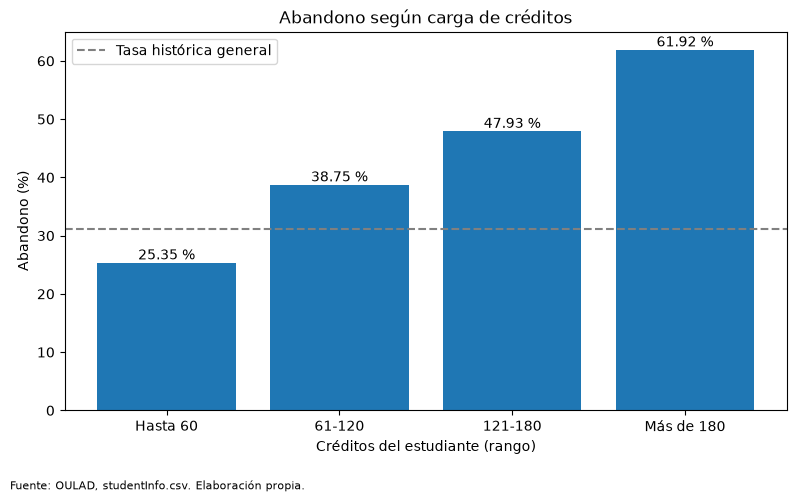

Diferencia entre extremos: 36.57 puntos porcentuales.
¿Las tasas crecen en todos los rangos?: True


In [6]:
# Hallazgo conservado del análisis original: abandono según carga de créditos.
# Este gráfico descriptivo usa todo el dataset; no se usa para seleccionar variables ni modelos.
rango = pd.cut(df.studied_credits, bins=[0,60,120,180,np.inf], include_lowest=True,
               labels=['Hasta 60','61-120','121-180','Más de 180'])
tabla_creditos = df.groupby(rango, observed=True).abandono.agg(['size','sum','mean'])
tabla_creditos.columns = ['Inscripciones','Abandonos','Tasa']
display(tabla_creditos.assign(**{'Tasa (%)':tabla_creditos.Tasa*100}).drop(columns='Tasa'))
fig, ax = plt.subplots()
barras = ax.bar(tabla_creditos.index.astype(str), tabla_creditos.Tasa*100)
ax.bar_label(barras, fmt='%.2f %%')
ax.axhline(df.abandono.mean()*100, ls='--', color='grey', label='Tasa histórica general')
ax.set(title='Abandono según carga de créditos', xlabel='Créditos del estudiante (rango)', ylabel='Abandono (%)')
ax.legend(); fig.text(.01,.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,.05,1,1)); plt.show()
print(f'Diferencia entre extremos: {(tabla_creditos.Tasa.iloc[-1]-tabla_creditos.Tasa.iloc[0])*100:.2f} puntos porcentuales.')
print('¿Las tasas crecen en todos los rangos?:', tabla_creditos.Tasa.is_monotonic_increasing)


---
## Modelado

### Pregunta 6. ¿Cuál es la variable objetivo, qué clases tiene y qué modelo utilizaron?

**Variable objetivo:** `abandono` (clasificación **binaria**), derivada de `final_result`:

- **1 = Abandono:** `final_result = Withdrawn`.
- **0 = No abandono:** `Pass`, `Fail` o `Distinction`.

**Modelos utilizados:** **ambos** modelos revisados en clase.

- **Regresión Logística** (`02_regresion_logistica.ipynb`): estima la **probabilidad** de
  abandono de cada estudiante y sus coeficientes indican qué variables aumentan o reducen el
  riesgo. Es pertinente porque una probabilidad permite ordenar a los estudiantes por riesgo.
- **Árbol de Decisión** (`03_arbol_decision.ipynb`): clasifica mediante **preguntas sencillas**
  (por ejemplo "¿tiene más de 82 créditos?"). Es pertinente porque sus reglas se pueden explicar
  fácilmente a coordinadores y tutores.

In [7]:
tabla = df.groupby(['final_result', 'abandono']).size().rename('Registros').reset_index()
print(tabla, '\n')
print(df['abandono'].value_counts().rename({0: 'No abandono (0)', 1: 'Abandono (1)'}))

  final_result  abandono  Registros
0  Distinction         0       3024
1         Fail         0       7052
2         Pass         0      12361
3    Withdrawn         1      10156 

abandono
No abandono (0)    22437
Abandono (1)       10156
Name: count, dtype: int64


### Pregunta 7. ¿Qué proporción usaron para entrenamiento, validación y prueba, y cómo hicieron la separación?
Se usa `GroupShuffleSplit` en dos pasos (70/30 de estudiantes; mitad del 30% para cada conjunto),
semilla 777. Las proporciones por **inscripciones** se calculan abajo y pueden variar ligeramente.
No se estratifica exactamente; se comprueba la prevalencia obtenida. Esto corresponde a predecir
inscripciones de estudiantes no vistos. Un reparto por filas puede compartir personas y patrones
entre entrenamiento y prueba incluso excluyendo su identificador; es riesgo de dependencia, no
prueba de que toda métrica previa estuviera inflada.

La misma partición se usa para ambos modelos. Preparación y búsqueda usan TRAIN; los cinco pliegues
de CV del árbol también separan estudiantes (`StratifiedGroupKFold`). Se elige por AUC, independiente
del umbral. VALIDACIÓN elige F1 de Logit y Youden del árbol; PRUEBA solo mide configuraciones
predefinidas. No se vuelven a entrenar los modelos con validación ni se seleccionan cortes con prueba.

In [8]:
partes, resumen_particiones = particionar(df)
conjuntos = preparar(df, partes)
display(df.head())
display(pd.DataFrame({'Cantidad': df.abandono.value_counts().sort_index(),
                     'Porcentaje (%)': df.abandono.value_counts(normalize=True).sort_index()*100}))
print('Dimensiones originales:', (len(df), df.shape[1]-1))
print('Estudiantes únicos:', df.id_student.nunique())
display(resumen_particiones)
print('Intersecciones de estudiantes entre conjuntos: 0 (verificado con assertions).')
# Auditoría del procedimiento anterior: estratificar filas no separa estudiantes.
a, resto = train_test_split(np.arange(len(df)), test_size=.30, random_state=777, stratify=df.abandono)
v, b = train_test_split(resto, test_size=.50, random_state=777, stratify=df.iloc[resto].abandono)
print('Estudiantes compartidos TRAIN/TEST en el método anterior:',
      len(set(df.iloc[a].id_student) & set(df.iloc[b].id_student)))


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,abandono
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0


,Cantidad,Porcentaje (%)
abandono,,
0,22437,68.8399
1,10156,31.1601


Dimensiones originales: (32593, 12)
Estudiantes únicos: 28785


,Conjunto,Inscripciones,Estudiantes,Inscripciones (%),Abandono (%)
0,Entrenamiento,22802,20149,69.9598,31.1552
1,Validación,4933,4318,15.1352,30.9345
2,Prueba,4858,4318,14.9050,31.4121


Intersecciones de estudiantes entre conjuntos: 0 (verificado con assertions).
Estudiantes compartidos TRAIN/TEST en el método anterior: 787


### Pregunta 8. ¿Cuáles son las variables más importantes y cómo determinaron su importancia?
Logit conserva la máxima verosimilitud de `statsmodels`, con intercepto y una categoría de referencia
por variable para evitar colinealidad. Se comprueba rango completo y convergencia. El árbol usa una
grilla de profundidades 3, 5, 8 y 10; mínimo por hoja 20 o 50; mínimo para dividir 2 o 100, con cinco
pliegues por grupos. Las cifras y parámetros definitivos se calculan aquí.

Los coeficientes y odds ratio representan asociaciones condicionadas a los demás predictores.
La importancia del árbol suma la reducción de impureza. La interpretación de créditos y las
categorías de referencia se imprimen debajo; ninguna de estas medidas establece causalidad.

In [9]:
logit = ajustar_logit(conjuntos, df, partes)
arbol = ajustar_arbol(conjuntos, df, partes)
umbrales, tabla_validacion, tabla_youden = elegir_umbrales(conjuntos, logit, arbol)
print('Logit convergió:', logit['modelo'].mle_retvals['converged'])
print('Columnas transformadas:', len(arbol['nombres']))
print('Mejores hiperparámetros:', arbol['busqueda'].best_params_)
print('AUC medio CV (solo TRAIN):', arbol['busqueda'].best_score_)
print('Umbrales elegidos solo con validación:', umbrales)


Logit convergió: True
Columnas transformadas: 41
Mejores hiperparámetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 50, 'modelo__min_samples_split': 2}
AUC medio CV (solo TRAIN): 0.6455652839383413
Umbrales elegidos solo con validación: {'Logit': 0.3, 'Árbol': 0.3018867924528302}


Referencias categóricas de Logit: {'code_module': 'AAA', 'code_presentation': '2013B', 'gender': 'F', 'region': 'East Anglian Region', 'highest_education': 'A Level or Equivalent', 'imd_band': '0-10%', 'age_band': '0-35', 'disability': 'N'}


,Coeficiente,Odds ratio,OR inferior 95%,OR superior 95%,p-value (cluster estudiante)
const,-2.3519,0.0952,0.0698,0.1298,0.0000
numericas__num_of_prev_attempts,-0.0212,0.9790,0.9180,1.0441,0.5185
numericas__studied_credits,0.0081,1.0082,1.0074,1.0090,0.0000
categoricas__code_module_BBB,0.6367,1.8903,1.4632,2.4421,0.0000
categoricas__code_module_CCC,1.3816,3.9811,3.0730,5.1576,0.0000
categoricas__code_module_DDD,0.9862,2.6810,2.0789,3.4576,0.0000
categoricas__code_module_EEE,0.5829,1.7912,1.3705,2.3409,0.0000
categoricas__code_module_FFF,0.6923,1.9983,1.5509,2.5749,0.0000
categoricas__code_module_GGG,-0.3223,0.7245,0.5405,0.9710,0.0310
categoricas__code_presentation_2013J,0.0978,1.1028,0.9986,1.2178,0.0533


Por crédito adicional, las odds se multiplican por 1.0082; por 60 créditos, por 1.628, manteniendo las demás variables.


,Importancia (%)
numericas__studied_credits,38.7534
categoricas__highest_education_Lower Than A Level,10.4192
categoricas__code_module_CCC,10.2543
categoricas__code_module_GGG,7.9160
categoricas__code_presentation_2014J,5.6415
categoricas__code_module_DDD,4.3004
categoricas__disability_Y,2.5053
categoricas__imd_band_20-30%,2.2588
categoricas__gender_M,1.9617
categoricas__code_presentation_2013J,1.5801


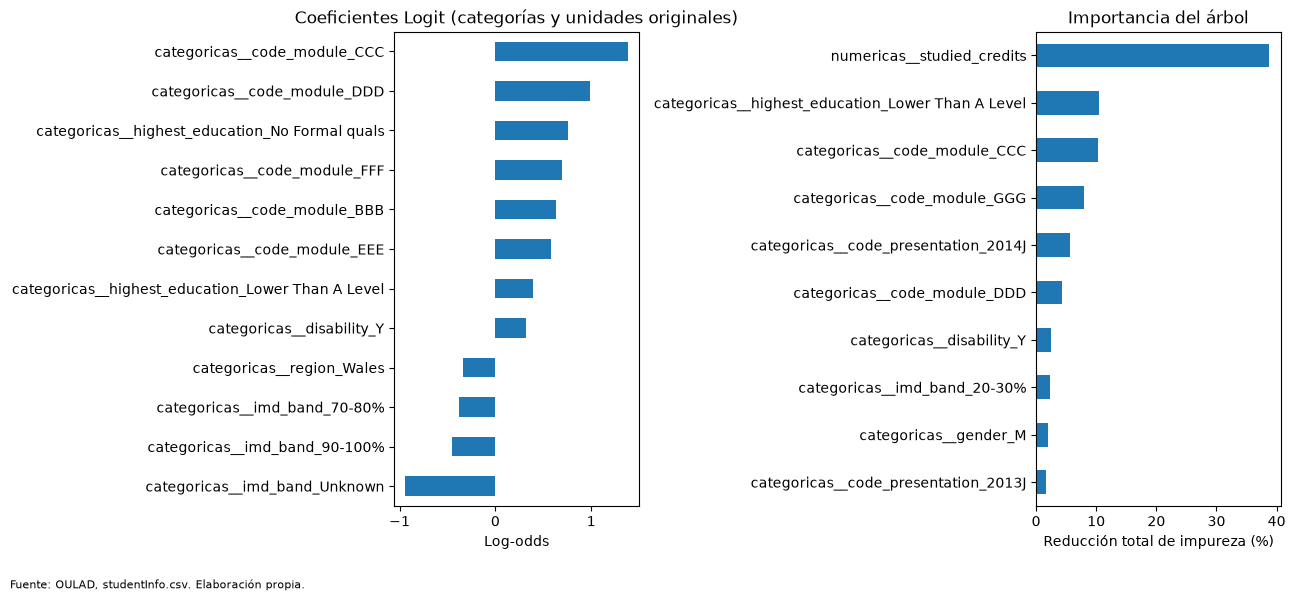

In [10]:
mostrar_importancias(logit, arbol)

### Pregunta 9. ¿Qué desempeño obtuvo el modelo en el conjunto de prueba?
Se muestran las cinco métricas solicitadas y las matrices, calculadas para los dos modelos y una
línea base mayoritaria entrenada en TRAIN. Se compara el umbral 0,50 con el seleccionado en
VALIDACIÓN: es una comparación reproducible de la mejora técnica y de su costo en falsas alertas.
La prioridad son los falsos negativos. El modelo de mayor recall es preferible bajo esa prioridad,
con la condición de que la institución pueda atender sus alertas. La reducción de abandono propuesta
en negocio necesita una intervención real; no puede inferirse de estas métricas predictivas.

In [11]:
display(tabla_validacion.loc[tabla_validacion.F1.idxmax()].to_frame("Selección F1 en validación"))
display(tabla_youden.loc[tabla_youden.Youden.idxmax()].to_frame("Selección Youden en validación"))

,Selección F1 en validación
Umbral,0.3000
Precision,0.4212
Recall,0.6835
F1,0.5212


,Selección Youden en validación
Umbral,0.3019
Sensibilidad,0.6402
Especificidad,0.5994
Youden,0.2396


,Umbral,Accuracy,Precision,Recall,F1,AUC-ROC,VN,FP,FN,VP
Modelo,,,,,,,,,,
Logit 0.50,0.5000,0.7089,0.6261,0.1822,0.2822,0.6884,3166,166,1248,278
Logit ajustado,0.3000,0.6097,0.4244,0.6809,0.5229,0.6884,1923,1409,487,1039
Árbol 0.50,0.5000,0.7032,0.5871,0.1855,0.2819,0.6649,3133,199,1243,283
Árbol ajustado,0.3019,0.6157,0.4257,0.6402,0.5114,0.6649,2014,1318,549,977
Mayoritaria,0.5000,0.6859,0.0000,0.0000,0.0000,0.5000,3332,0,1526,0


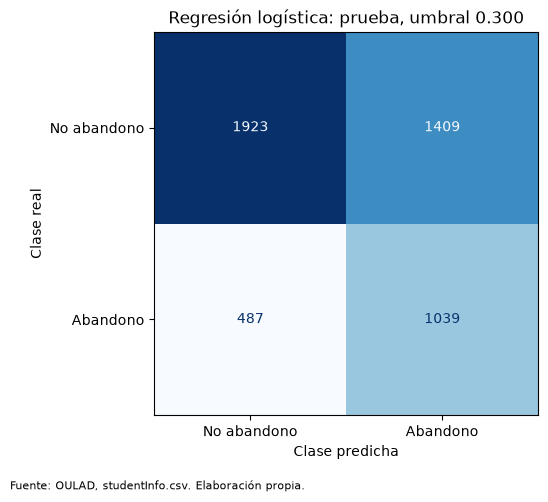

VP=1039: abandonos detectados. FN=487: abandonos sin alerta y posible ayuda omitida.
FP=1409: falsas alertas que consumen tutorías. VN=1923: no abandono correctamente clasificado.
              precision    recall  f1-score   support

 No abandono       0.80      0.58      0.67      3332
    Abandono       0.42      0.68      0.52      1526

    accuracy                           0.61      4858
   macro avg       0.61      0.63      0.60      4858
weighted avg       0.68      0.61      0.62      4858



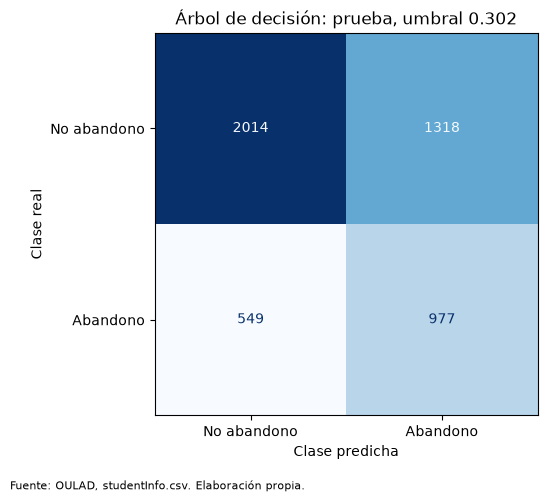

VP=977: abandonos detectados. FN=549: abandonos sin alerta y posible ayuda omitida.
FP=1318: falsas alertas que consumen tutorías. VN=2014: no abandono correctamente clasificado.
              precision    recall  f1-score   support

 No abandono       0.79      0.60      0.68      3332
    Abandono       0.43      0.64      0.51      1526

    accuracy                           0.62      4858
   macro avg       0.61      0.62      0.60      4858
weighted avg       0.67      0.62      0.63      4858



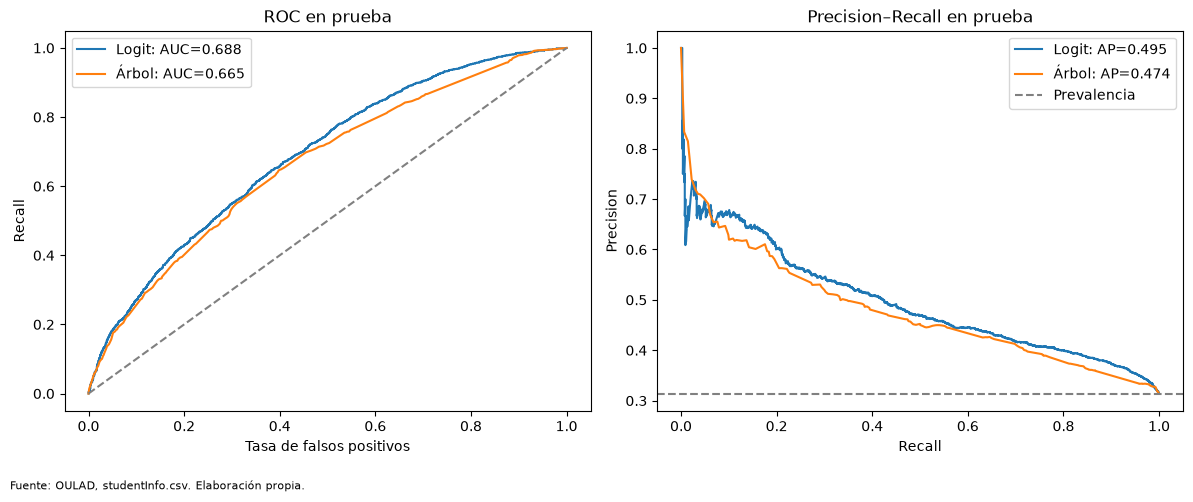

Para priorizar la detección de abandono se prefiere **Logit ajustado** en esta partición: Recall **0.6809**, F1 **0.5229**, **487 falsos negativos** y **1409 falsas alertas**. La capacidad de tutorías debe evaluarse antes del uso real.

Logit ajustado: meta Recall >= .75: False; meta F1 >= .70: False
Ajuste del umbral frente a .50: ΔRecall=+0.4987, ΔF1=+0.2407, ΔFP=+1243.
Árbol ajustado: meta Recall >= .75: False; meta F1 >= .70: False
Ajuste del umbral frente a .50: ΔRecall=+0.4548, ΔF1=+0.2295, ΔFP=+1119.
Ajustar el umbral modifica la detección; no demuestra reducir la tasa real de abandono.


In [12]:
resultados = evaluar(conjuntos, logit, arbol, umbrales)
display(resultados)
mostrar_errores(conjuntos, logit, umbrales['Logit'], 'Regresión logística')
mostrar_errores(conjuntos, arbol, umbrales['Árbol'], 'Árbol de decisión')
mostrar_curvas(conjuntos, {'Logit':logit, 'Árbol':arbol})
conclusiones(resultados)


### Límites y mejora siguiente
La reducción del umbral es una mejora técnica medible frente a 0,50; las diferencias de Recall, F1
y falsas alertas se calculan arriba. **No se demuestra reducir el abandono real**, ni se alcanza una
meta por haber cambiado las reglas de evaluación. Las cifras históricas de otros repartos no son
comparables directamente con esta prueba por estudiantes.

Los falsos negativos omiten apoyo a personas que finalmente abandonan; los falsos positivos
consumen contactos y tutorías. No se conoce un costo monetario que permita optimizar esa decisión.
Youden equilibra sensibilidad y especificidad, no minimiza específicamente el costo de FN; F1
equilibra precisión y recall. La elección de un umbral con una cuota de tutorías o un costo explícito
requiere una nueva validación, sin volver a ajustar sobre esta prueba.

La importancia por impureza puede favorecer variables con más puntos de corte. Los coeficientes
no se comparan como ranking absoluto cuando las unidades son distintas. Sus asociaciones no son
causales. Logit usa errores estándar agrupados por estudiante para considerar las inscripciones
dependientes dentro de TRAIN. Las probabilidades no se han validado con un estudio de calibración.

Como trabajo futuro, agregar actividad de las primeras semanas de `studentVle` y evaluaciones
tempranas de `studentAssessment`, fijando una fecha de corte, y evaluar en una cohorte futura
con estudiantes separados. Esa mejora **todavía no fue ejecutada**. OULAD corresponde a Open
University; extrapolar a UNIFRANZ requiere datos locales y validación, así como revisar diferencias
de error entre grupos y confirmar la disponibilidad temporal de todos los predictores.


### Pregunta 10. ¿Qué visualización permite entender cómo toma decisiones el modelo?
El gráfico muestra dos niveles iniciales y la celda imprime **una ruta completa real de validación**,
con todos sus valores, condiciones, hoja y decisión final. Izquierda significa `<=`; derecha, `>`.
Para una dummy, `<=0.5` indica ausencia de esa categoría. `samples` cuenta inscripciones TRAIN;
`value` muestra proporciones [no abandono, abandono]. La profundidad visual se recorta por legibilidad,
pero la ruta impresa llega a la hoja real. La clase del dibujo usa mayoría (0,50), mientras que la
alerta del proyecto usa Youden: pueden diferir y la celda muestra el criterio correcto.

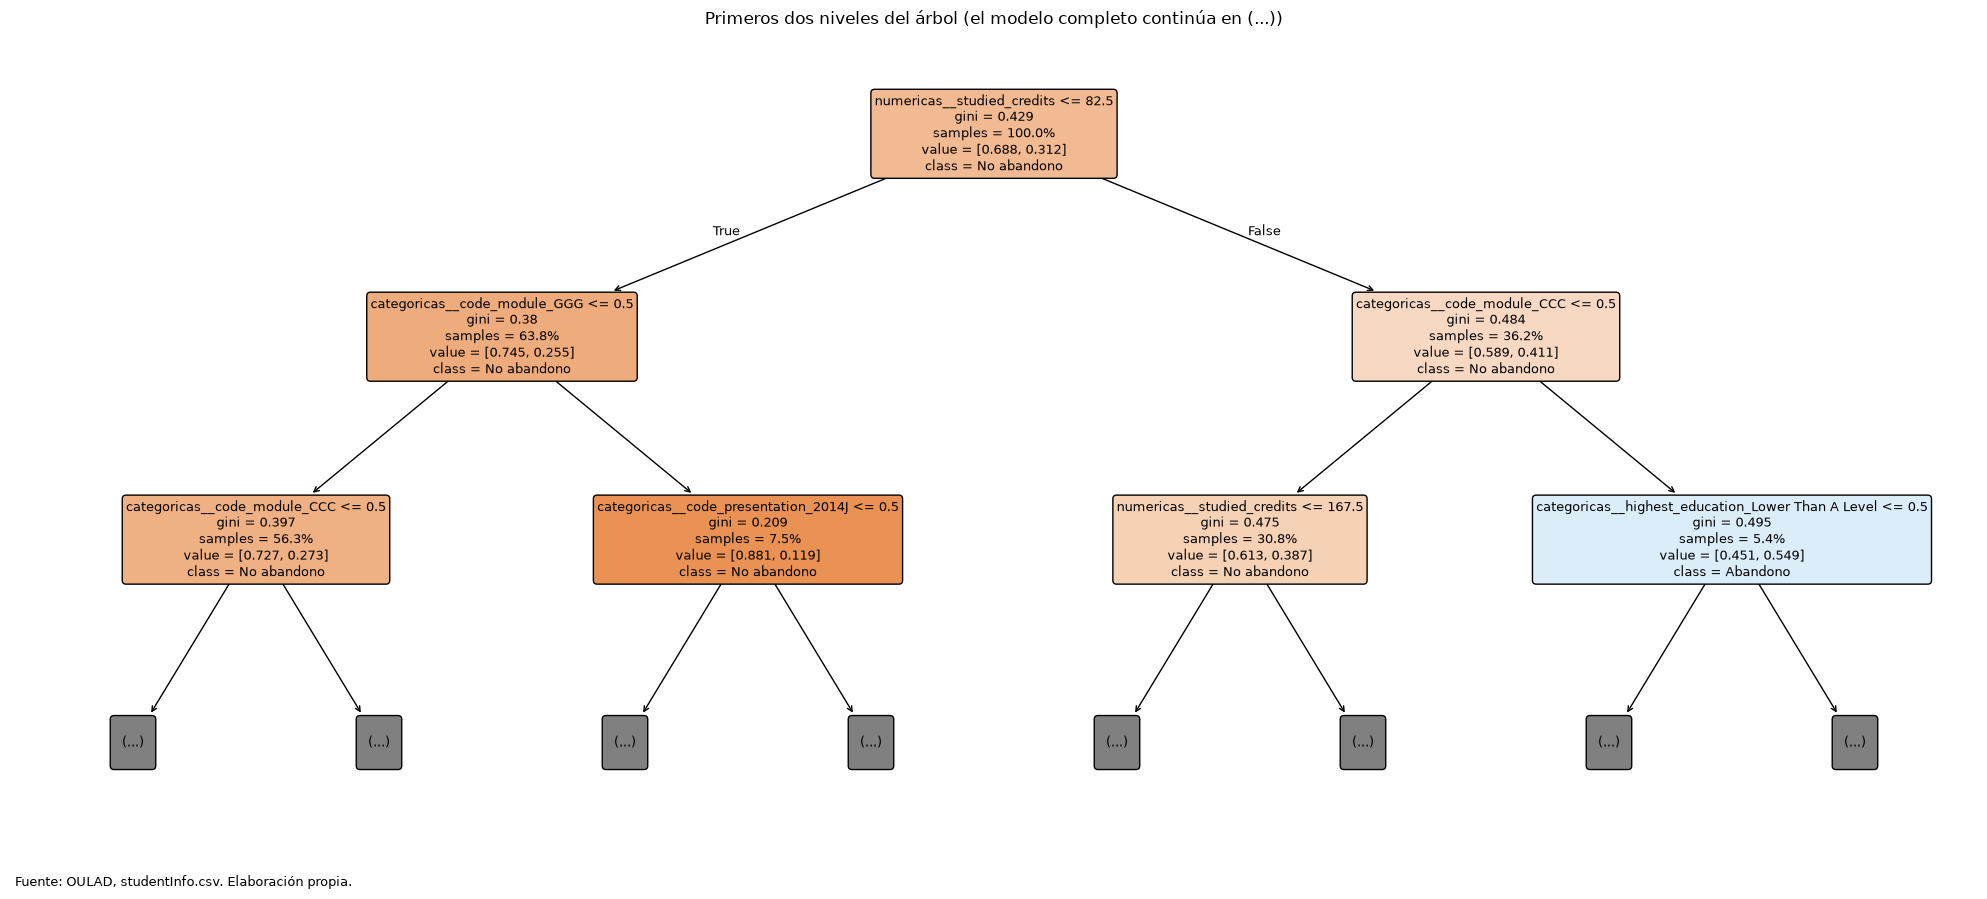

,num_of_prev_attempts,studied_credits,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,disability
9,0,60,AAA,2013J,M,North Region,Post Graduate Qualification,NaN,55<=,N


Ruta completa de una inscripción real de validación:
Nodo 0: numericas__studied_credits = 60 <= 82.500; seguir izquierda.
Nodo 1: categoricas__code_module_GGG = 0 <= 0.500; seguir izquierda.
Nodo 2: categoricas__code_module_CCC = 0 <= 0.500; seguir izquierda.
Nodo 3: categoricas__highest_education_Lower Than A Level = 0 <= 0.500; seguir izquierda.
Nodo 4: categoricas__highest_education_No Formal quals = 0 <= 0.500; seguir izquierda.
Nodo 5: categoricas__disability_Y = 0 <= 0.500; seguir izquierda.
Nodo 6: categoricas__code_module_DDD = 0 <= 0.500; seguir izquierda.
Nodo 7: categoricas__region_London Region = 0 <= 0.500; seguir izquierda.
Nodo 8: categoricas__imd_band_10-20 = 0 <= 0.500; seguir izquierda.
Nodo 9: categoricas__region_North Western Region = 0 <= 0.500; seguir izquierda.
Hoja 10: 3441 registros TRAIN, P(abandono)=0.1869.
Con umbral de validación 0.3019, la alerta final es 0.
La clase mayoritaria del gráfico usa 0.50; la alerta operativa usa el umbral ajustado.


In [13]:
mostrar_arbol(arbol, conjuntos, df, partes, umbrales['Árbol'])

## Referencias y reproducción
- [OULAD, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset)
- [Kuzilek, Hlosta y Zdrahal (2017), artículo del dataset](https://doi.org/10.1038/sdata.2017.171)
- [Repositorio del docente](https://github.com/ealaurel/MINERIA_DATOS_2026_2): `h3_01_Regresion_Logistica.ipynb`,
  `h3_02_Arboles_de_decisión_clasificacion.ipynb`, `h3_03_ejemplo_entrega_tarea.ipynb`
  y `h3_03_evaluacion1_grupal_proyecto_crisp_dm copy.md`.
- [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

Instalar `requirements.txt`, abrir Jupyter y ejecutar **Restart Kernel and Run All Cells**.
El código de `Codigo/metodologia.py` se incorpora en cada entrega para que ninguna dependa de
variables o resultados de otro notebook. Los resultados se obtienen del CSV local con semilla 777.
